<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/string_theory/string_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*String Theory* — `string_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# String Theory — Comprehensive Visualization Notebook
**Based on D. Tong, DAMTP Cambridge · string.pdf**

8 key visualizations, one per chapter (Ch 1–8).

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 1 | Worldsheet geometry and symmetries of the Polyakov action |
| 2 | Ch 2 | Torus moduli space and UV finiteness (modular domain) |
| 3 | Ch 3 | T-duality: KK vs winding modes, radius inversion |
| 4 | Ch 4 | Conformal map: cylinder → complex plane |
| 5 | Ch 5 | One-loop partition function and Dedekind η(τ) |
| 6 | Ch 6 | Veneziano amplitude and Regge behaviour |
| 7 | Ch 7 | α′ expansion and dilaton dynamics |
| 8 | Ch 8 | Compactification on S¹: KK modes and winding spectrum |

Run **Setup** first, then any plot cell independently.


In [1]:
# ── Setup ────────────────────────────────────────────────────────────────
# matplotlib mathtext 미지원 명령어 → 대체
# \\implies → \\Rightarrow
# \\iff → \\Leftrightarrow
# \\xleftrightarrow{T} → \\overset{T}{\\longleftrightarrow}
# \\stackrel → \\overset
# \\begin{pmatrix} → 성분 나열
# \\alpha\' → \\alpha^{\\prime}
# {\\alpha^{\\prime}}^n  (이중 위첨자 주의)
# axhline(transform=transAxes) → ax.plot([x0,x1],[y,y], transform=transAxes)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D  # noqa
from scipy.special import beta as Beta
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
SKYB = '#89c4f4'; YELL = '#f9c74f'; GREEN = '#90ee90'
RED  = '#e07070'; PURP = '#c792ea'; ORAN = '#e8a838'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG,  'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.25,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': SKYB, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

os.makedirs('string_visualizations', exist_ok=True)

def save(name, fig):
    fig.savefig(f'string_visualizations/{name}', dpi=150,
                bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: string_visualizations/{name}')

print('Setup complete.')


Setup complete.


## Plot 1: Ch 1 · Classical String — Worldsheet Geometry


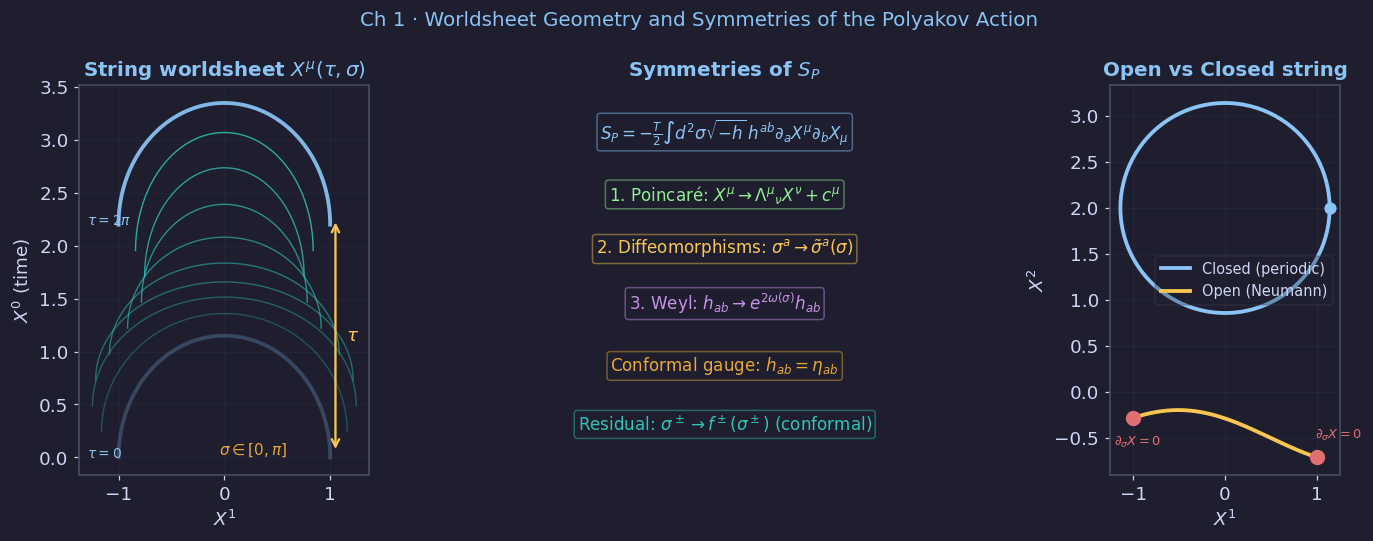

Saved: string_visualizations/ch01_fig01_worldsheet_symmetries.png


In [2]:
# ── fig01: Worldsheet geometry and symmetries ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Ch 1 · Worldsheet Geometry and Symmetries of the Polyakov Action',
             color=SKYB, fontsize=13)

# Left: string sweeps worldsheet in spacetime
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'String worldsheet $X^\mu(\tau,\sigma)$', color=SKYB)
sigma = np.linspace(0, np.pi, 80)
tau_vals = np.linspace(0, 2*np.pi, 10)
for i, tau in enumerate(tau_vals):
    x = np.cos(sigma) * (1 + 0.25*np.sin(tau))
    y = np.sin(sigma) * (1 + 0.15*np.cos(tau))
    alpha = 0.25 + 0.75*i/len(tau_vals)
    col = SKYB if i in [0, len(tau_vals)-1] else TEAL
    lw = 2.5 if i in [0, len(tau_vals)-1] else 0.9
    ax.plot(x, y + 0.35*tau, color=col, lw=lw, alpha=alpha)

# worldsheet coordinate arrows
ax.annotate('', xy=(1.05, 0.05), xytext=(1.05, 0.35*2*np.pi+0.05),
            arrowprops=dict(arrowstyle='<->', color=YELL, lw=1.5))
ax.text(1.15, 0.35*np.pi, r'$\tau$', color=YELL, fontsize=12)
ax.text(-0.05, 0.03, r'$\sigma\in[0,\pi]$', color=ORAN, fontsize=10)
ax.text(-1.3, 0.0,   r'$\tau=0$',    color=SKYB, fontsize=9)
ax.text(-1.3, 0.35*2*np.pi, r'$\tau=2\pi$', color=SKYB, fontsize=9)
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^0$ (time)')
ax.grid(True, alpha=0.15); ax.set_aspect('equal')

# Middle: Polyakov action symmetries
ax = axes[1]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Symmetries of $S_P$', color=SKYB)
items = [
    (0.5, 0.88, r'$S_P = -\frac{T}{2}\int d^2\sigma\sqrt{-h}\,h^{ab}\partial_a X^\mu\partial_b X_\mu$', SKYB),
    (0.5, 0.72, r'1. Poincaré: $X^\mu\to\Lambda^\mu{}_\nu X^\nu+c^\mu$', GREEN),
    (0.5, 0.58, r'2. Diffeomorphisms: $\sigma^a\to\tilde\sigma^a(\sigma)$', YELL),
    (0.5, 0.44, r'3. Weyl: $h_{ab}\to e^{2\omega(\sigma)}h_{ab}$', PURP),
    (0.5, 0.28, r'Conformal gauge: $h_{ab}=\eta_{ab}$', ORAN),
    (0.5, 0.13, r'Residual: $\sigma^\pm\to f^\pm(\sigma^\pm)$ (conformal)', TEAL),
]
for x_, y_, txt, col in items:
    ax.text(x_, y_, txt, ha='center', va='center', fontsize=11, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.45))

# Right: open vs closed string boundary conditions
ax = axes[2]; ax.set_facecolor(BG)
ax.set_title('Open vs Closed string', color=SKYB)
sigma_o = np.linspace(0, np.pi, 200)
sigma_c = np.linspace(0, 2*np.pi, 200)
tau_plot = 0.8

# Closed: periodic
x_cl = np.cos(sigma_c) * (1 + 0.2*np.cos(tau_plot))
y_cl = np.sin(sigma_c) * (1 + 0.2*np.sin(tau_plot)) + 2.0
ax.plot(x_cl, y_cl, color=SKYB, lw=2.5, label='Closed (periodic)')
ax.plot(x_cl[0], y_cl[0], 'o', color=SKYB, ms=7)

# Open: endpoints free
amp = 0.3
x_op = sigma_o/np.pi * 2 - 1
y_op = amp * np.sin(sigma_o + tau_plot) - 0.5
ax.plot(x_op, y_op, color=YELL, lw=2.5, label='Open (Neumann)')
ax.plot([x_op[0],x_op[-1]], [y_op[0],y_op[-1]], 'o', color=RED, ms=9, zorder=6)
ax.text(x_op[0]+0.3, y_op[0]-0.3, r'$\partial_\sigma X=0$', fontsize=8.5,
        color=RED, ha='right')
ax.text(x_op[-1]-0.02, y_op[-1]+0.2, r'$\partial_\sigma X=0$', fontsize=8.5,
        color=RED, ha='left')

ax.legend(fontsize=9.5); ax.grid(True, alpha=0.2); ax.set_aspect('equal')
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^2$')

plt.tight_layout()
save('ch01_fig01_worldsheet_symmetries.png', fig)


## Plot 2: Ch 2 · Quantum String — Torus Moduli Space and UV Finiteness


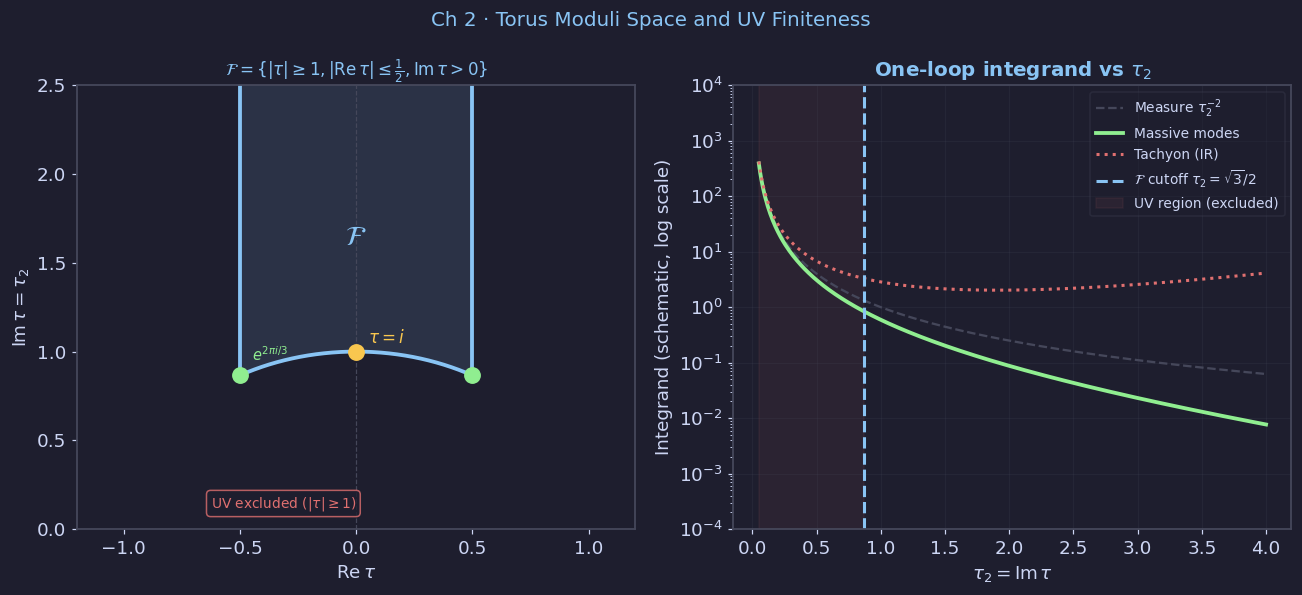

Saved: string_visualizations/ch02_fig03_modular_domain.png


In [3]:

# ── fig03: Modular fundamental domain ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r'Ch 2 · Torus Moduli Space and UV Finiteness',
             color=SKYB, fontsize=13)

# Left: fundamental domain in upper half-plane
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Fundamental domain $\mathcal{F}$ of $SL(2,\mathbb{Z})$', color=SKYB)
ax.set_xlim(-1.2, 1.2); ax.set_ylim(0, 2.5)

# Draw fundamental domain
tau1 = np.linspace(-0.5, 0.5, 300)
# Arc |tau|=1
theta_arc = np.linspace(np.pi*2/3, np.pi/3, 300)
arc_x = np.cos(theta_arc)
arc_y = np.sin(theta_arc)

# Fill fundamental domain
theta_fill = np.linspace(np.pi*2/3, np.pi/3, 200)
xf = np.concatenate([[-0.5], np.cos(theta_fill), [0.5, 0.5, -0.5]])
yf = np.concatenate([[2.5], np.sin(theta_fill), [np.sqrt(3)/2, 2.5, 2.5]])
ax.fill(xf, yf, color=SKYB, alpha=0.12)

ax.plot([-0.5, -0.5], [np.sqrt(3)/2, 2.5], color=SKYB, lw=2.5)
ax.plot([ 0.5,  0.5], [np.sqrt(3)/2, 2.5], color=SKYB, lw=2.5)
ax.plot(arc_x, arc_y, color=SKYB, lw=2.5)
ax.axhline(0, color=EDGE, lw=0.8, ls=':')
ax.axvline(0, color=EDGE, lw=0.8, ls='--')

# Special points
ax.plot([0], [1], 'o', color=YELL, ms=10, zorder=6)
ax.text(0.05, 1.05, r'$\tau=i$', color=YELL, fontsize=11)
ax.plot([-0.5], [np.sqrt(3)/2], 'o', color=GREEN, ms=10, zorder=6)
ax.text(-0.45, np.sqrt(3)/2+0.08, r'$e^{2\pi i/3}$', color=GREEN, fontsize=9.5)
ax.plot([0.5], [np.sqrt(3)/2], 'o', color=GREEN, ms=10, zorder=6)

ax.text(0, 1.6, r'$\mathcal{F}$', ha='center', fontsize=18,
        color=SKYB, fontweight='bold')
ax.text(0.5, 0.05, r'UV excluded ($|\tau|\geq 1$)',
        ha='right', transform=ax.transAxes, fontsize=9, color=RED,
        bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.8))

ax.set_xlabel(r'$\mathrm{Re}\,\tau$')
ax.set_ylabel(r'$\mathrm{Im}\,\tau = \tau_2$')
ax.set_title(r'$\mathcal{F}=\{|\tau|\geq 1, |\mathrm{Re}\,\tau|\leq\frac{1}{2}, \mathrm{Im}\,\tau>0\}$',
             color=SKYB, fontsize=11)

# Right: integrand behaviour
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'One-loop integrand vs $\tau_2$', color=SKYB)
tau2_vals = np.linspace(0.05, 4, 400)
# Schematic: massive modes damp exp(-4pi*tau2*N/24), tachyon grows
# Z ~ tau2^{-13} / |eta|^{48}; eta -> e^{-pi*tau2/12} for large tau2
# So Z ~ tau2^{-13} * e^{+4pi*tau2} (tachyon) * e^{-pi*tau2/6 * sum}
# Schematic for illustration
Z_massive = np.exp(-2*np.pi*tau2_vals/12)   # contribution from first massive mode
Z_tachyon = np.exp(+4*np.pi*tau2_vals/12)   # tachyon (IR divergent in principle)
Z_measure = tau2_vals**(-2)                   # d^2tau/tau2^2 measure

# Show how truncated domain saves us
tau2_cutoff = np.sqrt(3)/2  # Im tau >= sqrt(3)/2 in F

ax2.semilogy(tau2_vals, Z_measure, color=EDGE, lw=1.5, ls='--',
             label=r'Measure $\tau_2^{-2}$')
ax2.semilogy(tau2_vals, Z_massive * Z_measure, color=GREEN, lw=2.5,
             label=r'Massive modes')
ax2.semilogy(tau2_vals, np.clip(Z_tachyon*Z_measure, 1e-4, 1e4),
             color=RED, lw=2, ls=':', label='Tachyon (IR)')
ax2.axvline(tau2_cutoff, color=SKYB, lw=2, ls='--',
            label=r'$\mathcal{F}$ cutoff $\tau_2=\sqrt{3}/2$')
ax2.fill_between([0.05, tau2_cutoff], 1e-4, 1e4,
                 color=RED, alpha=0.07, label='UV region (excluded)')
ax2.set_xlabel(r'$\tau_2 = \mathrm{Im}\,\tau$')
ax2.set_ylabel('Integrand (schematic, log scale)')
ax2.legend(fontsize=9, loc='upper right')
ax2.set_ylim(1e-4, 1e4); ax2.grid(True, alpha=0.2)

plt.tight_layout()
save('ch02_fig03_modular_domain.png', fig)


## Plot 3: Ch 3 · Open Strings and D-Branes — T-duality and Radius Inversion


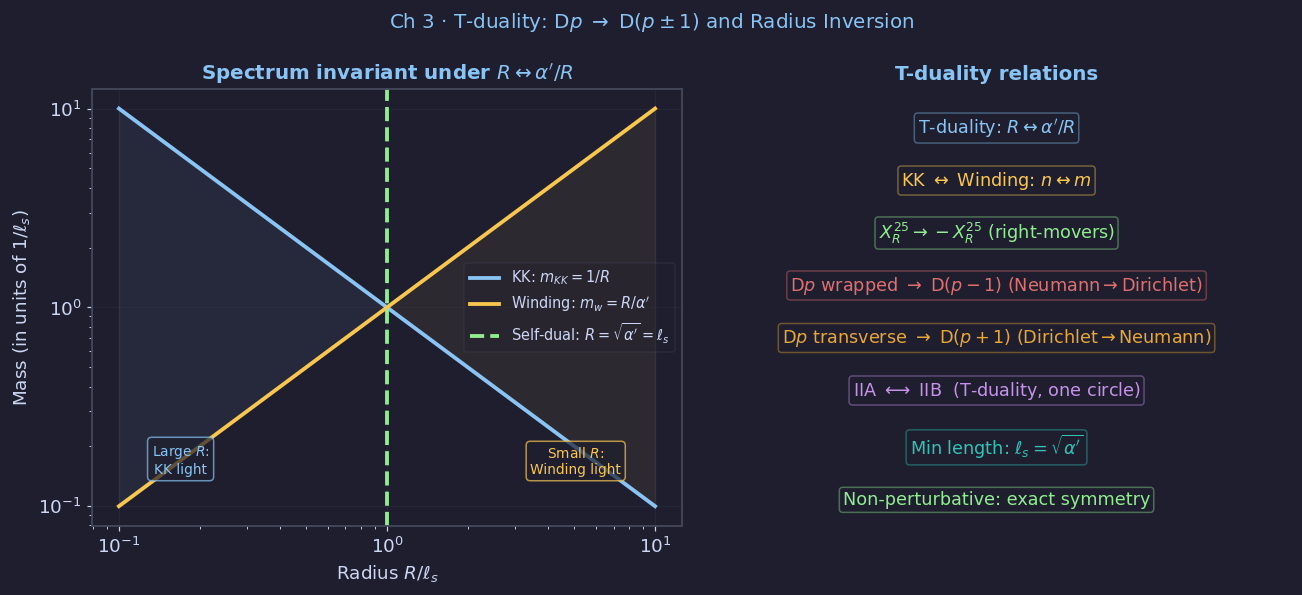

Saved: string_visualizations/ch03_fig03_tduality_dbranes.png


In [4]:

# ── fig03: T-duality — D-brane transformation ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r'Ch 3 · T-duality: D$p$ $\to$ D$(p\pm 1)$ and Radius Inversion',
             color=SKYB, fontsize=13)

# Left: radius inversion spectrum
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Spectrum invariant under $R\leftrightarrow\alpha^{\prime}/R$', color=SKYB)
R = np.logspace(-1, 1, 300)
alpha_prime = 1.0

# Lightest KK and winding modes
m_KK     = 1.0/R                    # n=1 KK
m_winding= R/alpha_prime             # m=1 winding

ax.loglog(R, m_KK,     color=SKYB, lw=2.5, label=r'KK: $m_{KK}=1/R$')
ax.loglog(R, m_winding,color=YELL, lw=2.5, label=r'Winding: $m_w=R/\alpha^{\prime}$')
ax.axvline(np.sqrt(alpha_prime), color=GREEN, lw=2.5, ls='--',
           label=r'Self-dual: $R=\sqrt{\alpha^{\prime}}=\ell_s$')
ax.fill_between(R, m_KK, m_winding,
                where=(R<np.sqrt(alpha_prime)), color=SKYB, alpha=0.07)
ax.fill_between(R, m_winding, m_KK,
                where=(R>np.sqrt(alpha_prime)), color=YELL, alpha=0.07)
ax.set_xlabel(r'Radius $R/\ell_s$')
ax.set_ylabel(r'Mass (in units of $1/\ell_s$)')
ax.legend(fontsize=9.5); ax.grid(True, alpha=0.2)
ax.text(0.15, 0.12, 'Large $R$:\nKK light', transform=ax.transAxes,
        fontsize=9, color=SKYB, ha='center',
        bbox=dict(boxstyle='round', fc=BG, ec=SKYB, alpha=0.7))
ax.text(0.82, 0.12, 'Small $R$:\nWinding light', transform=ax.transAxes,
        fontsize=9, color=YELL, ha='center',
        bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.7))

# Right: T-duality map
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('T-duality relations', color=SKYB)
items = [
    (0.5, 0.91, r'T-duality: $R\leftrightarrow\alpha^{\prime}/R$', SKYB),
    (0.5, 0.79, r'KK $\leftrightarrow$ Winding: $n\leftrightarrow m$', YELL),
    (0.5, 0.67, r'$X^{25}_R\to -X^{25}_R$ (right-movers)', GREEN),
    (0.5, 0.55, r'D$p$ wrapped $\to$ D$(p-1)$ (Neumann$\to$Dirichlet)', RED),
    (0.5, 0.43, r'D$p$ transverse $\to$ D$(p+1)$ (Dirichlet$\to$Neumann)', ORAN),
    (0.5, 0.31, r'IIA $\longleftrightarrow$ IIB  (T-duality, one circle)', PURP),
    (0.5, 0.18, r'Min length: $\ell_s=\sqrt{\alpha^{\prime}}$', TEAL),
    (0.5, 0.06, r'Non-perturbative: exact symmetry', GREEN),
]
for x_,y_,txt,col in items:
    ax2.text(x_,y_,txt,ha='center',va='center',fontsize=11.5,color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('ch03_fig03_tduality_dbranes.png', fig)


## Plot 4: Ch 4 · Conformal Field Theory — Cylinder to Complex Plane


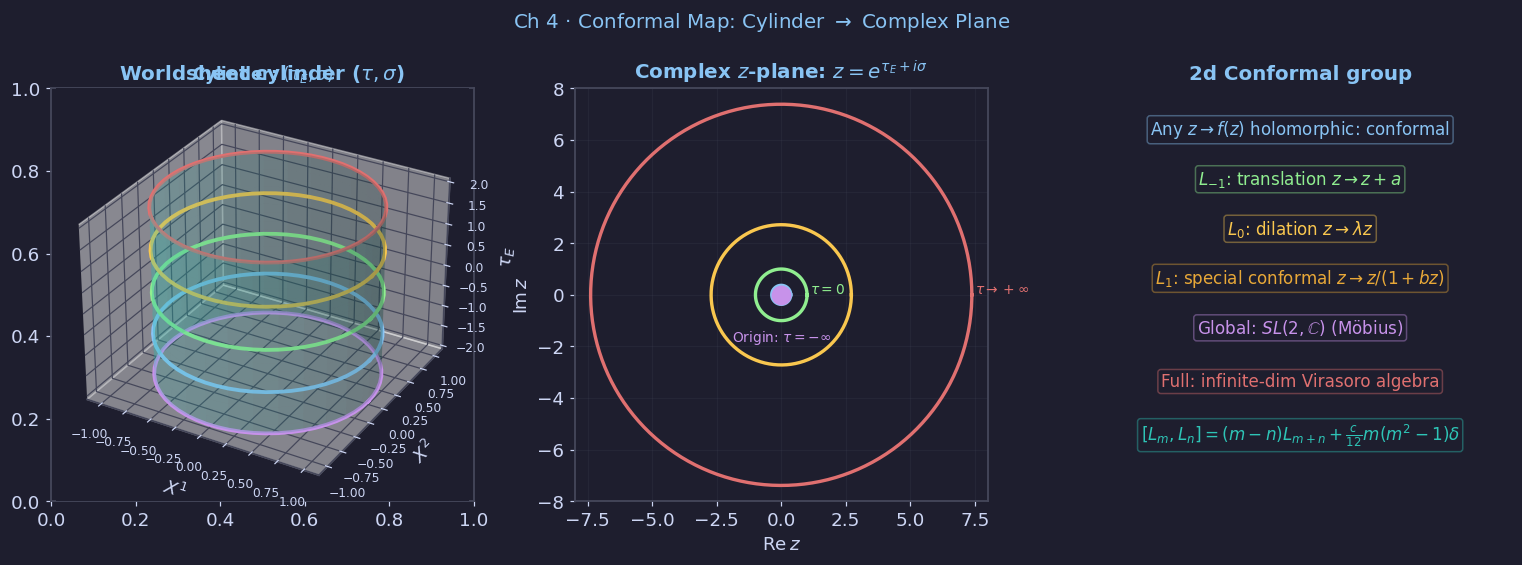

Saved: string_visualizations/ch04_fig01_cft_cylinder_plane.png


In [5]:

# ── fig01: Cylinder to complex plane mapping ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle(r'Ch 4 · Conformal Map: Cylinder $\to$ Complex Plane',
             color=SKYB, fontsize=13)

# Left: cylinder
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Worldsheet cylinder ($\tau,\sigma$)', color=SKYB)
from mpl_toolkits.mplot3d import Axes3D  # noqa
ax = fig.add_subplot(1,3,1, projection='3d')
ax.set_facecolor(BG)
theta = np.linspace(0, 2*np.pi, 60)
z_cyl = np.linspace(-2, 2, 20)
TH, ZC = np.meshgrid(theta, z_cyl)
XC = np.cos(TH)
YC = np.sin(TH)
ax.plot_surface(XC, YC, ZC, alpha=0.2, color=TEAL)
# Time slices
for z_val, col in [(-2, PURP), (-1, SKYB), (0, GREEN), (1, YELL), (2, RED)]:
    ax.plot(np.cos(theta), np.sin(theta), z_val, color=col, lw=2.5)
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^2$'); ax.set_zlabel(r'$\tau_E$')
ax.set_title(r'Cylinder: $(\tau_E,\sigma)$', color=SKYB, fontsize=11)
ax.tick_params(labelsize=8)

# Middle: complex z-plane
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Complex $z$-plane: $z=e^{\tau_E+i\sigma}$', color=SKYB)
# Draw circles (time slices)
for r_val, col, lbl in [#(np.e**(-2),  PURP, r'$\tau\to-\infty$'),
                         (np.e**(-1), SKYB, ''),
                         (1.0,        GREEN,r'$\tau=0$'),
                         (np.e**(1),  YELL, ''),
                         (np.e**(2),  RED,  r'$\tau\to+\infty$')]:
    th = np.linspace(0, 2*np.pi, 300)
    ax2.plot(r_val*np.cos(th), r_val*np.sin(th), color=col, lw=2.2)
    if lbl:
        ax2.text(r_val+0.12, 0.05, lbl, color=col, fontsize=9)
ax2.plot(0, 0, 'o', color=PURP, ms=12, zorder=8)
ax2.text(-1.9, -1.8, r'Origin: $\tau=-\infty$', color=PURP, fontsize=9)
ax2.set_xlim(-8, 8); ax2.set_ylim(-8, 8)
ax2.set_xlabel(r'$\mathrm{Re}\,z$'); ax2.set_ylabel(r'$\mathrm{Im}\,z$')
ax2.grid(True, alpha=0.2); ax2.set_aspect('equal')

# Right: conformal group
ax3 = axes[2]; ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_title('2d Conformal group', color=SKYB)
items = [
    (0.5, 0.90, r'Any $z\to f(z)$ holomorphic: conformal', SKYB),
    (0.5, 0.78, r'$L_{-1}$: translation $z\to z+a$', GREEN),
    (0.5, 0.66, r'$L_0$: dilation $z\to\lambda z$', YELL),
    (0.5, 0.54, r'$L_1$: special conformal $z\to z/(1+bz)$', ORAN),
    (0.5, 0.42, r'Global: $SL(2,\mathbb{C})$ (Möbius)', PURP),
    (0.5, 0.29, r'Full: infinite-dim Virasoro algebra', RED),
    (0.5, 0.16, r'$[L_m,L_n]=(m-n)L_{m+n}+\frac{c}{12}m(m^2-1)\delta$', TEAL),
]
for x_,y_,txt,col in items:
    ax3.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('ch04_fig01_cft_cylinder_plane.png', fig)


## Plot 5: Ch 5 · Polyakov Path Integral — One-Loop Partition Function


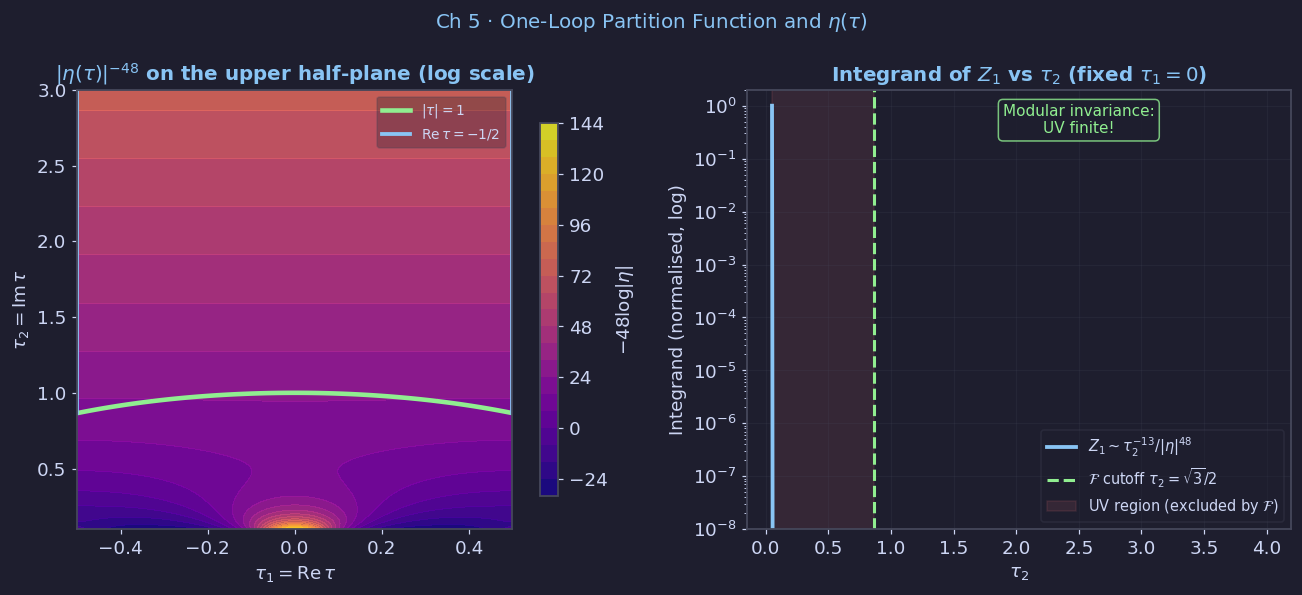

Saved: string_visualizations/ch05_fig02_partition_function_eta.png


In [6]:

# ── fig02: One-loop partition function and Dedekind eta ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r'Ch 5 · One-Loop Partition Function and $\eta(\tau)$',
             color=SKYB, fontsize=13)

# Left: Dedekind eta function |eta(tau)|^2 on upper half-plane
tau2_vals = np.linspace(0.1, 3.0, 300)
tau1_vals = np.linspace(-0.5, 0.5, 200)
T1, T2 = np.meshgrid(tau1_vals, tau2_vals)

# |eta(tau)|^2 = prod_{n=1}^inf |1-e^{2pi i tau}|^2 * e^{-pi*tau2/6}
# For large tau2: |eta| ~ e^{-pi*tau2/12}
# Compute numerically with finite product
def eta_abs2(tau1, tau2, Nmax=15):
    q = np.exp(2*np.pi*1j*(tau1 + 1j*tau2))
    result = np.abs(q)**(1/12)
    for n in range(1, Nmax+1):
        result *= np.abs(1 - q**n)**2
    return result

ETA2 = eta_abs2(T1, T2, Nmax=10)

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'$|\eta(\tau)|^{-48}$ on the upper half-plane (log scale)', color=SKYB)
log_eta = -48 * np.log(np.clip(ETA2, 1e-10, None))
cf = ax.contourf(tau1_vals, tau2_vals, log_eta, levels=25,
                 cmap='plasma', alpha=0.85)
plt.colorbar(cf, ax=ax, label=r'$-48\log|\eta|$', shrink=0.85)

# Fundamental domain boundary
theta_fd = np.linspace(np.pi*2/3, np.pi/3, 100)
ax.plot(np.cos(theta_fd), np.sin(theta_fd), color=GREEN, lw=3,
        label=r'$|\tau|=1$')
ax.plot([-0.5,-0.5],[np.sqrt(3)/2, 3.0], color=SKYB, lw=2.5,
        label=r'$\mathrm{Re}\,\tau=-1/2$')
ax.plot([ 0.5, 0.5],[np.sqrt(3)/2, 3.0], color=SKYB, lw=2.5)
ax.legend(fontsize=9, loc='upper right')
ax.set_xlabel(r'$\tau_1=\mathrm{Re}\,\tau$')
ax.set_ylabel(r'$\tau_2=\mathrm{Im}\,\tau$')

# Right: integrand vs tau2
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Integrand of $Z_1$ vs $\tau_2$ (fixed $\tau_1=0$)',
              color=SKYB)
tau2_plot = np.linspace(0.05, 4.0, 400)
eta2_plot = eta_abs2(0.0, tau2_plot, Nmax=15)
integrand = tau2_plot**(-13) / (eta2_plot**24)
integrand_norm = integrand / integrand.max()

ax2.semilogy(tau2_plot, integrand_norm, color=SKYB, lw=2.5,
             label=r'$Z_1\sim\tau_2^{-13}/|\eta|^{48}$')
tau2_cutoff = np.sqrt(3)/2
ax2.axvline(tau2_cutoff, color=GREEN, lw=2, ls='--',
            label=r'$\mathcal{F}$ cutoff $\tau_2=\sqrt{3}/2$')
ax2.fill_between([0.05, tau2_cutoff], 1e-10, 1e2,
                 color=RED, alpha=0.12, label=r'UV region (excluded by $\mathcal{F}$)')
ax2.set_xlabel(r'$\tau_2$')
ax2.set_ylabel('Integrand (normalised, log)')
ax2.legend(fontsize=9.5)
ax2.grid(True, alpha=0.2)
ax2.set_ylim(1e-8, 2)
ax2.text(2.5, 0.3,
         r'Modular invariance:' + '\n' + r'UV finite!',
         ha='center', fontsize=10, color=GREEN,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

plt.tight_layout()
save('ch05_fig02_partition_function_eta.png', fig)


## Plot 6: Ch 6 · String Interactions — Veneziano Amplitude


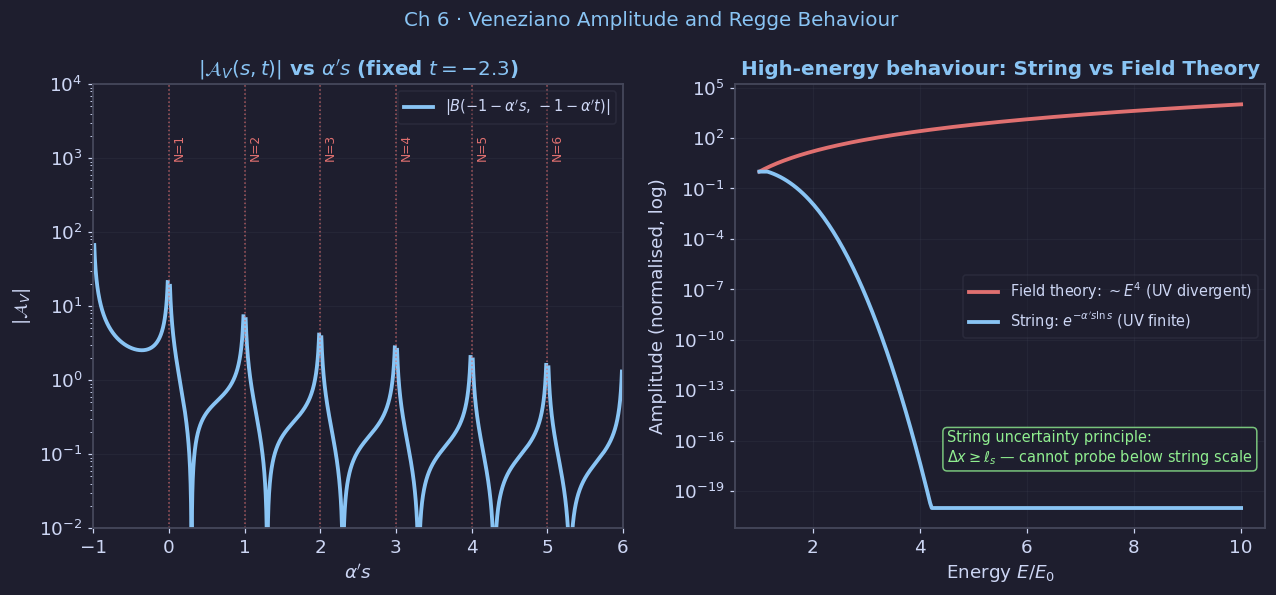

Saved: string_visualizations/ch06_fig01_veneziano.png


In [7]:
# ── fig01: Veneziano amplitude ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 6 · Veneziano Amplitude and Regge Behaviour', color=SKYB, fontsize=13)

from scipy.special import gamma as Gamma

# ── Left: Veneziano amplitude ─────────────────────────────────────────────
from scipy.special import beta as Beta

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'$|\mathcal{A}_V(s,t)|$ vs $\alpha^{\prime}s$ (fixed $t=-2.3$)',
             color=SKYB)

alpha_prime = 1.0
t_fixed = -2.3
b = -1 - alpha_prime * t_fixed   # = 1.3, 상수

pole_positions = np.arange(-1, 7, 1)   # s = -1, 0, 1, 2, 3, 4, 5, 6

for i in range(len(pole_positions) - 1):
    s_lo = pole_positions[i] + 0.015
    s_hi = pole_positions[i+1] - 0.015
    s_seg = np.linspace(s_lo, s_hi, 500)
    A_seg = np.zeros_like(s_seg)
    for j, s in enumerate(s_seg):
        a = -1 - alpha_prime * s
        try:
            val = abs(Beta(a, b))
            A_seg[j] = val if np.isfinite(val) else np.nan
        except Exception:
            A_seg[j] = np.nan
    # pole 근처 발산 부분은 nan으로 처리 (clip 대신)
    A_display = np.where(A_seg < 1e4, A_seg, np.nan)
    ax.semilogy(s_seg, A_display, color=SKYB, lw=2.5)

# legend용 dummy line
ax.semilogy([], [], color=SKYB, lw=2.5,
            label=r'$|B(-1-\alpha^{\prime}s,\,-1-\alpha^{\prime}t)|$')

# resonance pole 위치 표시
for n, s_pole in enumerate(pole_positions[1:-1]):   # s = 0, 1, 2, 3, 4, 5
    ax.axvline(s_pole, color=RED, lw=1, ls=':', alpha=0.7)
    ax.text(s_pole + 0.05, 1e3, f'N={n+1}', fontsize=8,
            color=RED, rotation=90)

ax.set_xlabel(r'$\alpha^{\prime}s$')
ax.set_ylabel(r'$|\mathcal{A}_V|$')
ax.legend(fontsize=9.5)
ax.grid(True, alpha=0.2)
ax.set_xlim(-1, 6)
ax.set_ylim(1e-2, 1e4)



# ── Right: high-energy behaviour ──────────────────────────────────────────
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title('High-energy behaviour: String vs Field Theory', color=SKYB)
E = np.linspace(1, 10, 300)

# Field theory: power-law growth
A_FT = E**4

# String: Virasoro-Shapiro fixed-angle behaviour
# |A| ~ exp(-alpha'/2 * (s*ln s + t*ln|t| + u*ln|u|))
# Fixed angle: s large, t = -s*sin^2(theta/2), u = -s*cos^2(theta/2)
theta = np.pi / 3
s_str = E**2
t_str = s_str * np.sin(theta/2)**2   # |t|, positive
u_str = s_str * np.cos(theta/2)**2   # |u|, positive

# Exponent (all arguments positive now)
exponent = (alpha_prime / 2) * (
    s_str * np.log(s_str) +
    t_str * np.log(t_str) +
    u_str * np.log(u_str)
)
A_string = np.exp(-np.clip(exponent, 0, 200))

ax2.semilogy(E, A_FT / A_FT[0], color=RED, lw=2.5,
             label=r'Field theory: $\sim E^4$ (UV divergent)')
ax2.semilogy(E, np.clip(A_string / A_string[0], 1e-20, None),
             color=SKYB, lw=2.5,
             label=r'String: $e^{-\alpha^{\prime}s\ln s}$ (UV finite)')

ax2.set_xlabel(r'Energy $E/E_0$')
ax2.set_ylabel('Amplitude (normalised, log)')
ax2.legend(fontsize=9.5); ax2.grid(True, alpha=0.2)
ax2.text(0.40, 0.15,
         'String uncertainty principle:\n'
         r'$\Delta x \geq \ell_s$ — cannot probe below string scale',
         transform=ax2.transAxes, fontsize=9.5, color=GREEN,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

plt.tight_layout()
save('ch06_fig01_veneziano.png', fig)

## Plot 7: Ch 7 · Low-Energy Effective Action — Dilaton Dynamics


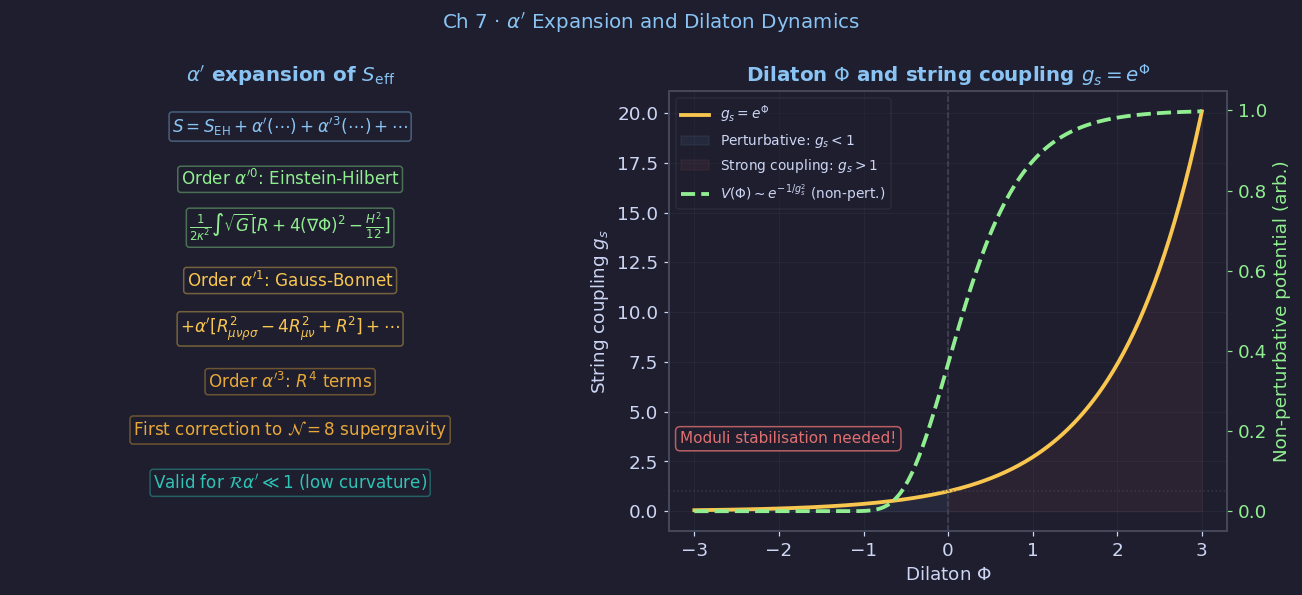

Saved: string_visualizations/ch07_fig02_alpha_prime_dilaton.png


In [8]:

# ── fig02: alpha' expansion and dilaton potential ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r"Ch 7 · $\alpha'$ Expansion and Dilaton Dynamics",
             color=SKYB, fontsize=13)

# Left: alpha' expansion schematic
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r"$\alpha'$ expansion of $S_{\rm eff}$", color=SKYB)
items = [
    (0.5, 0.92, r'$S=S_{\rm EH}+\alpha^{\prime}(\cdots)+{\alpha^{\prime}}^{3}(\cdots)+\cdots$', SKYB),
    (0.5, 0.80, r'Order ${\alpha^{\prime}}^{0}$: Einstein-Hilbert', GREEN),
    (0.5, 0.69, r'$\frac{1}{2\kappa^2}\int\sqrt{G}[R+4(\nabla\Phi)^2-\frac{H^2}{12}]$', GREEN),
    (0.5, 0.57, r'Order ${\alpha^{\prime}}^{1}$: Gauss-Bonnet', YELL),
    (0.5, 0.46, r'$+\alpha^{\prime}[R_{\mu\nu\rho\sigma}^2-4R_{\mu\nu}^2+R^2]+\cdots$', YELL),
    (0.5, 0.34, r'Order ${\alpha^{\prime}}^{3}$: $R^4$ terms', ORAN),
    (0.5, 0.23, r'First correction to $\mathcal{N}=8$ supergravity', ORAN),
    (0.5, 0.11, r'Valid for $\mathcal{R}\alpha^{\prime}\ll 1$ (low curvature)', TEAL),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

# Right: dilaton potential and string coupling
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Dilaton $\Phi$ and string coupling $g_s=e^\Phi$', color=SKYB)
Phi = np.linspace(-3, 3, 300)
gs  = np.exp(Phi)
# Perturbative regime: g_s << 1  <-> Phi << 0
# Non-perturbative: instanton V ~ exp(-1/g_s^2)
V_pert = np.zeros_like(Phi)  # flat at tree level
V_np   = np.exp(-np.exp(-2*Phi))  # schematic non-perturbative

ax2_twin = ax2.twinx()
ax2_twin.set_facecolor(BG)
ax2.plot(Phi, gs, color=YELL, lw=2.5, label=r'$g_s=e^\Phi$')
ax2.axvline(0, color=EDGE, lw=1, ls='--')
ax2.axhline(1, color=EDGE, lw=1, ls=':', alpha=0.6)
ax2.fill_between(Phi, 0, gs, where=(Phi<0), color=SKYB, alpha=0.07,
                 label='Perturbative: $g_s<1$')
ax2.fill_between(Phi, 0, gs, where=(Phi>0), color=RED, alpha=0.07,
                 label='Strong coupling: $g_s>1$')
ax2_twin.plot(Phi, V_np, color=GREEN, lw=2.5, ls='--',
              label=r'$V(\Phi)\sim e^{-1/g_s^2}$ (non-pert.)')
ax2_twin.set_ylabel(r'Non-perturbative potential (arb.)', color=GREEN)
ax2_twin.tick_params(axis='y', colors=GREEN)

ax2.set_xlabel(r'Dilaton $\Phi$')
ax2.set_ylabel(r'String coupling $g_s$')
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1+lines2, labels1+labels2, fontsize=9, loc='upper left')
ax2.text(0.02, 0.2, r'Moduli stabilisation needed!',
         transform=ax2.transAxes, fontsize=10, color=RED,
         bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.8))
ax2.grid(True, alpha=0.2)

plt.tight_layout()
save('ch07_fig02_alpha_prime_dilaton.png', fig)


## Plot 8: Ch 8 · Compactification — KK Modes and Winding Spectrum


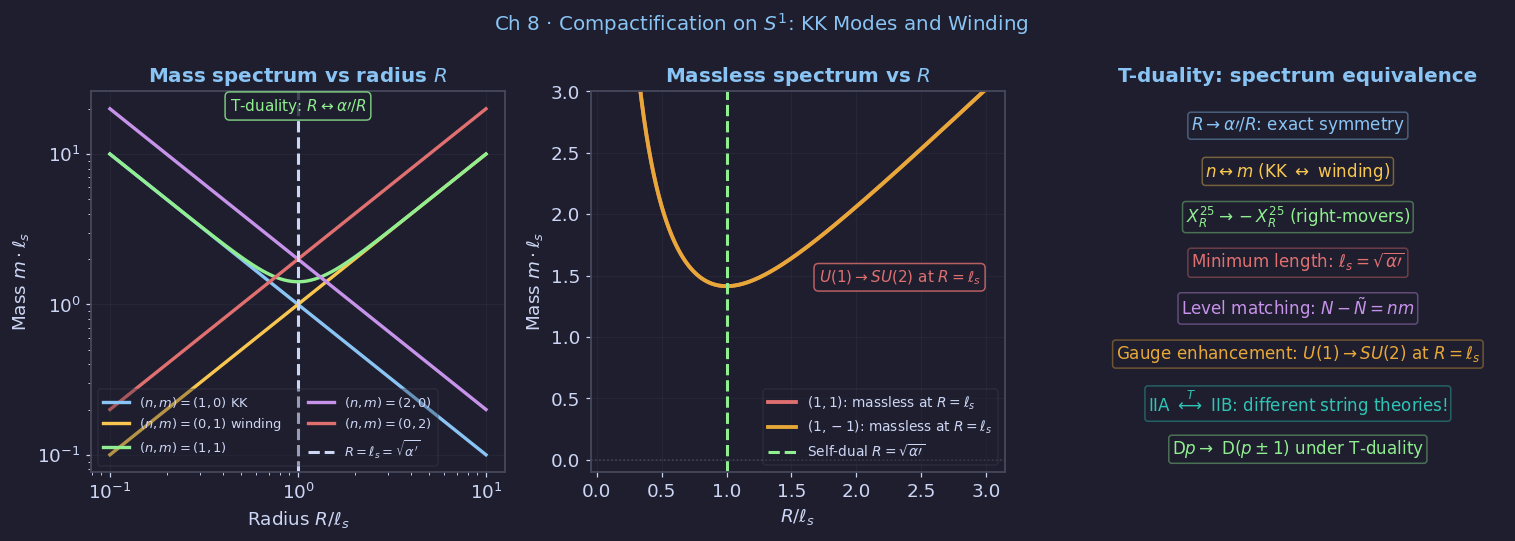

Saved: string_visualizations/ch08_fig01_kk_winding_spectrum.png


In [9]:

# ── fig01: KK modes and winding — mass spectrum ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Ch 8 · Compactification on $S^1$: KK Modes and Winding',
             color=SKYB, fontsize=13)

alpha_prime = 1.0

# Left: mass spectrum vs R for (n,m) modes
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Mass spectrum vs radius $R$', color=SKYB)
R_vals = np.logspace(-1, 1, 300)

for (n, m, col, lbl) in [
    (1, 0, SKYB,  r'$(n,m)=(1,0)$ KK'),
    (0, 1, YELL,  r'$(n,m)=(0,1)$ winding'),
    (1, 1, GREEN, r'$(n,m)=(1,1)$'),
    (2, 0, PURP,  r'$(n,m)=(2,0)$'),
    (0, 2, RED,   r'$(n,m)=(0,2)$'),
]:
    m2 = (n/R_vals)**2 + (m*R_vals/alpha_prime)**2
    ax.loglog(R_vals, np.sqrt(m2), color=col, lw=2.2, label=lbl)

ax.axvline(np.sqrt(alpha_prime), color=FG, lw=2, ls='--',
           label=r'$R=\ell_s=\sqrt{\alpha^{\prime}}$')
ax.set_xlabel(r'Radius $R/\ell_s$')
ax.set_ylabel(r'Mass $m\cdot\ell_s$')
ax.legend(fontsize=8.5, ncol=2); ax.grid(True, alpha=0.2)
ax.text(0.5, 0.95, r'T-duality: $R\leftrightarrow\alpha\prime/R$',
        transform=ax.transAxes, ha='center', fontsize=10, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

# Middle: self-dual radius and gauge enhancement
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Massless spectrum vs $R$', color=SKYB)
R_lin = np.linspace(0.1, 3.0, 300)
# KK and winding masses that go to zero at R_sd
for (n, m, col, lbl) in [(1,1,RED,r'$(1,1)$: massless at $R=\ell_s$'),
                          (1,-1,ORAN,r'$(1,-1)$: massless at $R=\ell_s$')]:
    pL = n/R_lin + m*R_lin/alpha_prime
    pR = n/R_lin - m*R_lin/alpha_prime
    # mass^2 = pL^2/2 + pR^2/2 + N + Ntilde - 2 (for N=Ntilde=1)
    m2 = pL**2/2 + pR**2/2 - 2 + 2  # N=Ntilde=1 contribution = 2, -2 cancels
    m2_actual = (pL**2 + pR**2)/2   # mass^2 at N=Ntilde=1
    ax2.plot(R_lin, np.sqrt(np.abs(m2_actual)), color=col, lw=2.5, label=lbl)

ax2.axvline(np.sqrt(alpha_prime), color=GREEN, lw=2, ls='--',
            label=r'Self-dual $R=\sqrt{\alpha\prime}$')
ax2.axhline(0, color=EDGE, lw=1, ls=':')
ax2.set_xlabel(r'$R/\ell_s$')
ax2.set_ylabel(r'Mass $m\cdot\ell_s$')
ax2.set_ylim(-0.1, 3); ax2.legend(fontsize=9); ax2.grid(True, alpha=0.2)
ax2.text(0.55, 0.50,
         r'$U(1)\to SU(2)$ at $R=\ell_s$',
         transform=ax2.transAxes, fontsize=10, color=RED,
         bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.8))

# Right: T-duality diagram
ax3 = axes[2]; ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_title('T-duality: spectrum equivalence', color=SKYB)
items = [
    (0.5, 0.91, r'$R\to\alpha\prime/R$: exact symmetry', SKYB),
    (0.5, 0.79, r'$n\leftrightarrow m$ (KK $\leftrightarrow$ winding)', YELL),
    (0.5, 0.67, r'$X^{25}_R\to-X^{25}_R$ (right-movers)', GREEN),
    (0.5, 0.55, r'Minimum length: $\ell_s=\sqrt{\alpha\prime}$', RED),
    (0.5, 0.43, r'Level matching: $N-\tilde N=nm$', PURP),
    (0.5, 0.31, r'Gauge enhancement: $U(1)\to SU(2)$ at $R=\ell_s$', ORAN),
    (0.5, 0.18, r'IIA $\overset{T}{\longleftrightarrow}$ IIB: different string theories!', TEAL),
    (0.5, 0.06, r'D$p\to$ D$(p\pm 1)$ under T-duality', GREEN),
]
for x_,y_,txt,col in items:
    ax3.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('ch08_fig01_kk_winding_spectrum.png', fig)


## Download All Visualizations


In [10]:
# ── Download all visualizations as a zip ────────────────────────────────
import shutil

shutil.make_archive('string_visualizations', 'zip', 'string_visualizations')

try:
    from google.colab import files
    files.download('string_visualizations.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — files saved to string_visualizations/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
